## Distributed Grep - Performance testing

This notebook will provide an insight into the performance tests carried out on my distributed grep program showing how changing different metrics on the cluster like the number of executors, number of cores per executor, memory and dataset size would change the runtime of the spark job.

I set a stable key word, 'queen', within the distributed grep program so that there were not many different outputs that would skew the data I found.

In [2]:
import pandas as pd

performanceData_executors =  pd.read_excel("FYP_performance_testing.xlsx", "DistributedGrep perf - Executor")

performanceData_executors

,num_executors,executor_cores,executor_memory,runtime_seconds
0,1,1,4G,17384
1,2,1,4G,7552
2,3,1,4G,4954
3,4,1,4G,3585
4,5,1,4G,2924
5,6,1,4G,2410
6,7,1,4G,2154
7,8,1,4G,1859
8,9,1,4G,1785
9,10,1,4G,1646


Text(0, 0.5, 'Runtime (seconds)')

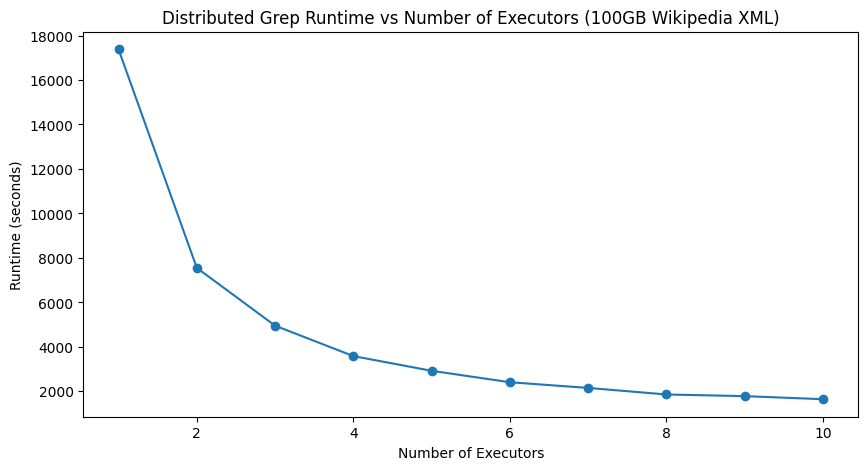

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize = (10,5))

plt.plot(performanceData_executors["num_executors"],
         performanceData_executors["runtime_seconds"],
         marker="o")

plt.title("Distributed Grep Runtime vs Number of Executors (100GB Wikipedia XML)")
plt.xlabel("Number of Executors")
plt.ylabel("Runtime (seconds)")

## Break Down of Results - executors:

### Large decrease in the runtime

- The performance improvement from adding just one more executor is significant
- As more are added the rate at which the runtime improves decreases
- The runtime then seems to plataeu showing that adding more executors is not changing much

### Speedup Scaling - diminishing returns

- There are a number of sequential computations that must occur that must take place and adding more executors will not be as impactful